### 参数设置

In [1]:
# -*- coding: utf-8 -*-


import datetime
import re
import warnings

import numpy as np
import pandas as pd
from jqdata import *
from jqdata import finance
try:
    from jqdata import query
except ImportError:
    pass

warnings.filterwarnings('ignore')
pd.set_option('display.unicode.east_asian_width', True)
pd.set_option('display.width', 220)
pd.set_option('display.max_rows', 500)
pd.set_option('display.max_columns', 50)

START_DATE = '2024-01-01'                   # 回测起始日
END_DATE = '2026-12-20'                     # 回测结束日, 晚于今天则截断到今天
PRODUCTS = ['IH', 'IF', 'IC', 'IM']         # 上证50 / 沪深300 / 中证500 / 中证1000
TOP_N_LIST = [5, 10, 15, 20]                # 跟踪席位排名 <= n
TRADING_DAYS_PER_YEAR = 242                 # 年化交易日数
DRAW_FIGURES = True                         # 是否画净值图
LARGE_CAP_PRODUCTS = ['IH', 'IF']           # 大盘蓝筹: 趋势跟踪; IC/IM 中小盘: 趋势反转
RANK_TYPE_LONG, RANK_TYPE_SHORT = 501002, 501003   # 龙虎榜: 持买单量排名 / 持卖单量排名

### 交易日历

In [2]:
backtest_start = pd.to_datetime(START_DATE).date()
backtest_end = min(pd.to_datetime(END_DATE).date(), datetime.date.today())
print('回测区间: %s ~ %s' % (backtest_start, backtest_end))

calendar_start = backtest_start - datetime.timedelta(days=30)   # 多取30天, 用于计算前一日因子
trade_days = pd.to_datetime([str(day) for day in get_trade_days(start_date=calendar_start, end_date=backtest_end)])
previous_day_map = dict(zip(trade_days[1:], trade_days[:-1]))   # 交易日 -> 前一交易日
next_day_map = dict(zip(trade_days[:-1], trade_days[1:]))       # 交易日 -> 后一交易日
backtest_days = trade_days[trade_days >= pd.Timestamp(backtest_start)]
all_futures = get_all_securities(['futures'])

回测区间: 2024-01-01 ~ 2026-11-12


### 当季合约与原始数据获取

In [4]:
def get_quarter_contracts(product):
    """某品种全部季月(3/6/9/12)合约及其上市、到期日"""
    pattern = re.compile(r'^%s(\d{2})(\d{2})\.CCFX$' % product)
    rows = []
    for code in all_futures.index:
        matched = pattern.match(code)
        if matched and int(matched.group(2)) % 3 == 0:
            rows.append((code, pd.Timestamp(all_futures.loc[code, 'start_date']),
                         pd.Timestamp(all_futures.loc[code, 'end_date'])))
    return pd.DataFrame(rows, columns=['code', 'start', 'end'])


def build_current_quarter_series(product):
    """每个交易日对应的当季合约: 最近且尚未到期的季月合约 (到期日当天已切换到下一个当季)"""
    contracts = get_quarter_contracts(product)
    current_quarter = {}
    for day in backtest_days:
        alive = contracts[(contracts['start'] <= day) & (contracts['end'] > day)]
        if len(alive) > 0:
            current_quarter[day] = alive.sort_values('end').iloc[0]['code']
    return pd.Series(current_quarter)


def fetch_price(code, start, end):
    """日频开盘价、收盘价、持仓量"""
    price = get_price(code, start_date=start.strftime('%Y-%m-%d'), end_date=end.strftime('%Y-%m-%d'),
                      frequency='daily', fields=['open', 'close', 'open_interest'])
    price.index = pd.to_datetime(price.index)
    return price


def fetch_seat_rank(code, start, end):
    """龙虎榜多空前20席位持仓; 接口单次最多4000行, 按90天切片查询"""
    table = finance.FUT_MEMBER_POSITION_RANK
    frames = []
    slice_start = start
    while slice_start <= end:
        slice_end = min(slice_start + datetime.timedelta(days=89), end)
        sql = query(table.day, table.rank, table.rank_type_ID, table.indicator).filter(
            table.code == code,
            table.rank_type_ID.in_([RANK_TYPE_LONG, RANK_TYPE_SHORT]),
            table.day >= slice_start, table.day <= slice_end)
        frame = finance.run_query(sql)
        if frame is not None and len(frame) > 0:
            frames.append(frame)
        slice_start = slice_end + datetime.timedelta(days=1)
    return pd.concat(frames) if frames else None

### 因子特征构建

In [5]:
def calc_top_n_seat_sums(seat_rank):
    """前 n 名席位的多头持仓合计 long_n、空头持仓合计 short_n"""
    seat_rank = seat_rank.copy()
    seat_rank['day'] = pd.to_datetime(seat_rank['day'])
    seat_rank['indicator'] = seat_rank['indicator'].astype(float)
    sums = {}
    for top_n in TOP_N_LIST:
        pivot = seat_rank[seat_rank['rank'] <= top_n].groupby(['day', 'rank_type_ID'])['indicator'].sum().unstack()
        if RANK_TYPE_LONG in pivot.columns:
            sums['long_%d' % top_n] = pivot[RANK_TYPE_LONG]
        if RANK_TYPE_SHORT in pivot.columns:
            sums['short_%d' % top_n] = pivot[RANK_TYPE_SHORT]
    return pd.DataFrame(sums)


def build_contract_features(code, window_start, window_end):
    """单个合约的日度因子: 价格变化、净持仓变化、多/空持仓变化、多/空持仓占比"""
    features = fetch_price(code, window_start, window_end)
    seat_rank = fetch_seat_rank(code, window_start.date(), window_end.date())
    if seat_rank is not None:
        features = features.join(calc_top_n_seat_sums(seat_rank))
    for top_n in TOP_N_LIST:
        for side in ('long', 'short'):
            if '%s_%d' % (side, top_n) not in features.columns:
                features['%s_%d' % (side, top_n)] = np.nan
    features['price_change'] = features['close'].pct_change()
    for top_n in TOP_N_LIST:
        long_position, short_position = features['long_%d' % top_n], features['short_%d' % top_n]
        features['net_change_%d' % top_n] = (long_position - short_position).diff()   # 净持仓变化
        features['long_change_%d' % top_n] = long_position.diff()                     # 多头持仓变化
        features['short_change_%d' % top_n] = short_position.diff()                   # 空头持仓变化
        features['long_ratio_%d' % top_n] = long_position / features['open_interest'] # 多头占比
        features['short_ratio_%d' % top_n] = short_position / features['open_interest']
    return features


def build_product_features(product):
    """
    行索引 = 持仓日 u。因子取自前一交易日 t (t日收盘后得到席位数据, t+1日开盘交易);
    next_return = 当季合约 u 日开盘 -> u+1 日开盘收益 (t+1早上操作, t+2早上切换)。
    """
    current_quarter = build_current_quarter_series(product)
    if len(current_quarter) == 0:
        return None
    parts = []
    for code in current_quarter.unique():
        hold_days = current_quarter[current_quarter == code].index
        factor_days = [previous_day_map.get(day, day) for day in hold_days]
        next_days = [next_day_map.get(day, day) for day in hold_days]
        window_start = previous_day_map.get(previous_day_map.get(hold_days[0], hold_days[0]), hold_days[0])
        window_end = next_day_map.get(hold_days[-1], hold_days[-1])
        print('  %s 当季合约 %s: %s ~ %s' % (product, code, hold_days[0].date(), hold_days[-1].date()))
        contract_features = build_contract_features(code, window_start, window_end)
        part = contract_features.reindex(factor_days)
        part.index = hold_days
        open_today = contract_features['open'].reindex(hold_days).values
        open_next = contract_features['open'].reindex(next_days).values
        next_return = open_next / open_today - 1.0
        next_return[np.array([a == b for a, b in zip(next_days, hold_days)])] = np.nan   # 最后一天无次日
        part['next_return'] = next_return
        part['contract'] = code
        parts.append(part)
    return pd.concat(parts).sort_index()


def load_all_features():
    """四个品种的因子表: {品种: DataFrame}"""
    all_features = {}
    for product in PRODUCTS:
        print('[%s]' % product)
        features = build_product_features(product)
        if features is None or len(features) == 0:
            print('  %s 区间内无可用合约, 跳过' % product)
            continue
        all_features[product] = features
    print('数据获取完成: ' + ', '.join(['%s %d个交易日' % (k, len(v)) for k, v in all_features.items()]))
    return all_features


all_features = load_all_features()

[IH]
  IH 当季合约 IH2403.CCFX: 2024-01-02 ~ 2024-03-14
  IH 当季合约 IH2406.CCFX: 2024-03-15 ~ 2024-06-20
  IH 当季合约 IH2409.CCFX: 2024-06-21 ~ 2024-09-19
  IH 当季合约 IH2412.CCFX: 2024-09-20 ~ 2024-12-19
  IH 当季合约 IH2503.CCFX: 2024-12-20 ~ 2025-03-20
  IH 当季合约 IH2506.CCFX: 2025-03-21 ~ 2025-06-19
  IH 当季合约 IH2509.CCFX: 2025-06-20 ~ 2025-09-18
  IH 当季合约 IH2512.CCFX: 2025-09-19 ~ 2025-12-18
  IH 当季合约 IH2603.CCFX: 2025-12-19 ~ 2026-03-19
  IH 当季合约 IH2606.CCFX: 2026-03-20 ~ 2026-06-18
  IH 当季合约 IH2609.CCFX: 2026-06-22 ~ 2026-09-17
  IH 当季合约 IH2612.CCFX: 2026-09-18 ~ 2026-11-12
[IF]
  IF 当季合约 IF2403.CCFX: 2024-01-02 ~ 2024-03-14
  IF 当季合约 IF2406.CCFX: 2024-03-15 ~ 2024-06-20
  IF 当季合约 IF2409.CCFX: 2024-06-21 ~ 2024-09-19
  IF 当季合约 IF2412.CCFX: 2024-09-20 ~ 2024-12-19
  IF 当季合约 IF2503.CCFX: 2024-12-20 ~ 2025-03-20
  IF 当季合约 IF2506.CCFX: 2025-03-21 ~ 2025-06-19
  IF 当季合约 IF2509.CCFX: 2025-06-20 ~ 2025-09-18
  IF 当季合约 IF2512.CCFX: 2025-09-19 ~ 2025-12-18
  IF 当季合约 IF2603.CCFX: 2025-12-19 ~ 2026-03-19
  I

### 信号、回测与评价函数

In [7]:
def make_signal(index, long_condition, short_condition):
    """多头=1, 空头=-1, 其余为 NaN (回测时向前填充 = 维持上一持仓)"""
    signal = pd.Series(np.nan, index=index)
    signal[long_condition.values] = 1.0
    signal[short_condition.values] = -1.0
    return signal


def run_backtest(features, signal):
    """持仓 = 信号向前填充; 日收益 = 持仓 * 次日开盘到次日开盘收益 (未计交易成本)"""
    position = signal.ffill().fillna(0.0)
    daily_return = (position * features['next_return']).dropna()
    return position.reindex(daily_return.index), daily_return


def calc_performance(daily_return, position):
    """净值及年化收益、年化波动率、夏普、最大回撤、胜率、信号次数、信号频率"""
    net_value = (1.0 + daily_return).cumprod()
    annual_return = daily_return.mean() * TRADING_DAYS_PER_YEAR
    annual_volatility = daily_return.std() * np.sqrt(TRADING_DAYS_PER_YEAR)
    holding = position != 0
    previous_position = position.shift(1)
    signal_count = int(((position != previous_position) & previous_position.notnull() & (previous_position != 0)).sum())
    metrics = {
        '年化收益': annual_return,
        '年化波动率': annual_volatility,
        '夏普比率': annual_return / annual_volatility if annual_volatility > 0 else np.nan,
        '最大回撤': (net_value / net_value.cummax() - 1.0).min(),
        '胜率': (daily_return[holding] > 0).mean() if holding.sum() > 0 else np.nan,
        '信号次数': signal_count,
        '信号频率': signal_count / float(len(daily_return)),
    }
    return net_value, metrics


def make_result_row(product, rank_label, metrics):
    """一行回测结果: 品种、席位排名标签 + 各项指标"""
    row = {'品种': product, '跟踪席位排名(<=n)': rank_label}
    row.update(metrics)
    return row


def backtest_strategy(signal_function, use_top_n):
    """
    对每个品种(及每个席位排名 n)回测, 并附上当季合约多头滚动持有的基准。
    返回: 回测结果 DataFrame、净值字典 {品种: {标签: 净值序列}}
    """
    rows, net_values = [], {}
    for product, features in all_features.items():
        net_values[product] = {}
        for top_n in (TOP_N_LIST if use_top_n else [None]):
            signal = signal_function(features, top_n, product)
            position, daily_return = run_backtest(features, signal)
            if len(daily_return) < 5:
                continue
            net_value, metrics = calc_performance(daily_return, position)
            rank_label = top_n if use_top_n else '无'
            rows.append(make_result_row(product, rank_label, metrics))
            net_values[product]['top%d' % top_n if use_top_n else 'strategy'] = net_value
        benchmark_position, benchmark_return = run_backtest(features, pd.Series(1.0, index=features.index))
        net_value, metrics = calc_performance(benchmark_return, benchmark_position)
        rows.append(make_result_row(product, '-', metrics))
        net_values[product]['benchmark'] = net_value
    columns = ['品种', '跟踪席位排名(<=n)', '年化收益', '年化波动率', '夏普比率', '最大回撤', '胜率', '信号次数', '信号频率']
    return pd.DataFrame(rows, columns=columns), net_values

### 结果展示函数

In [8]:
def format_result_table(result):
    """百分比/小数格式化, 仅用于显示"""
    shown = result.copy()
    for column in ['年化收益', '年化波动率', '最大回撤', '胜率', '信号频率']:
        if column in shown.columns:
            shown[column] = shown[column].map('{:.2%}'.format)
    shown['夏普比率'] = shown['夏普比率'].map('{:.2f}'.format)
    return shown


def plot_product_curves(title, curves_by_product):
    """2x2 子图, 每个品种一张"""
    import matplotlib.pyplot as plt
    figure, axes = plt.subplots(2, 2, figsize=(14, 8))
    for axis, product in zip(axes.flat, PRODUCTS):
        curves = curves_by_product.get(product)
        if not curves:
            continue
        for label, curve in curves.items():
            axis.plot(curve.index, curve.values, label=str(label))
        axis.set_title(product)
        axis.legend(fontsize=8, ncol=3)
        axis.grid(True, alpha=0.3)
    figure.suptitle(title)
    plt.show()


def show_strategy_report(title, result, net_values):
    """打印回测表, 并画净值图"""
    print('\n' + '=' * 30 + ' %s ' % title + '=' * 30)
    print(format_result_table(result).to_string(index=False))
    print('注: 基准策略为当季合约多头滚动持有, 跟踪席位排名记为"-"; 未计交易成本。')
    if DRAW_FIGURES:
        plot_product_curves(title, net_values)


all_strategy_results = {}    # 汇总各表结果, 供"总结"择优使用

### 一、持仓方向的指向性 —— 图1-4 前n席位持仓占比

图1-4 前n席位持仓占当季合约总持仓比例
品种  前n席位 多头占比均值 空头占比均值 多头占比最新 空头占比最新
 IH        5       37.89%       60.16%       43.52%       61.77%
 IH       10       53.30%       77.40%       57.16%       75.95%
 IH       15       63.62%       84.71%       66.59%       83.43%
 IH       20       70.88%       88.61%       73.72%       88.11%
 IF        5       40.29%       49.84%       40.69%       53.99%
 IF       10       54.13%       67.17%       55.60%       67.60%
 IF       15       63.44%       77.54%       65.21%       77.10%
 IF       20       70.44%       83.73%       72.08%       83.64%
 IC        5       44.85%       49.09%       44.44%       49.60%
 IC       10       59.45%       64.07%       57.08%       64.19%
 IC       15       68.21%       73.77%       65.98%       74.39%
 IC       20       74.47%       80.43%       72.99%       81.81%
 IM        5       39.66%       47.47%       41.58%       51.15%
 IM       10       53.62%       62.63%       55.91%       65.01%
 IM       15       62.74%      

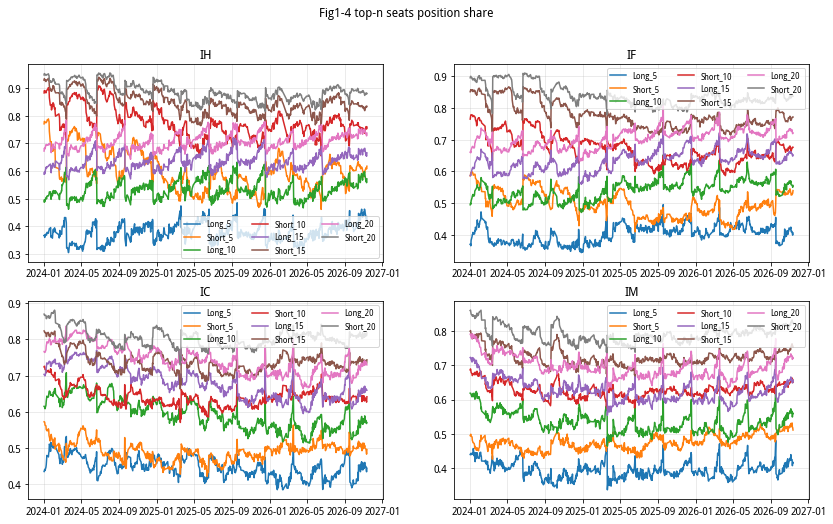

In [9]:
def calc_position_ratio_table(all_features):
    """前 n 席位多/空头持仓占当季合约总持仓比例: 区间均值与最新值"""
    rows, curves_by_product = [], {}
    for product, features in all_features.items():
        curves_by_product[product] = {}
        for top_n in TOP_N_LIST:
            long_ratio, short_ratio = features['long_ratio_%d' % top_n].dropna(), features['short_ratio_%d' % top_n].dropna()
            if len(long_ratio) == 0:
                continue
            rows.append([product, top_n, long_ratio.mean(), short_ratio.mean(), long_ratio.iloc[-1], short_ratio.iloc[-1]])
            curves_by_product[product]['Long_%d' % top_n] = long_ratio
            curves_by_product[product]['Short_%d' % top_n] = short_ratio
    table = pd.DataFrame(rows, columns=['品种', '前n席位', '多头占比均值', '空头占比均值', '多头占比最新', '空头占比最新'])
    return table, curves_by_product


position_ratio_table, ratio_curves = calc_position_ratio_table(all_features)
ratio_columns = ['多头占比均值', '空头占比均值', '多头占比最新', '空头占比最新']
shown_ratio_table = position_ratio_table.copy()
for column in ratio_columns:
    shown_ratio_table[column] = shown_ratio_table[column].map('{:.2%}'.format)
print('图1-4 前n席位持仓占当季合约总持仓比例')
print(shown_ratio_table.to_string(index=False))
if DRAW_FIGURES:
    plot_product_curves('Fig1-4 top-n seats position share', ratio_curves)

### 一、持仓方向的指向性 —— 净持仓的择时效果 (表1)


============================== 表1 净持仓跟踪策略回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5   14.39%     19.58%     0.74  -20.29%  51.95%       316   45.73%
 IH                10    0.79%     19.60%     0.04  -30.53%  48.34%       315   45.59%
 IH                15    8.16%     19.59%     0.42  -20.29%  49.64%       313   45.30%
 IH                20   12.76%     19.58%     0.65  -20.29%  49.64%       320   46.31%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5   15.72%     21.10%     0.74  -27.68%  53.11%       344   49.78%
 IF                10   -2.37%     21.12%    -0.11  -39.95%  49.06%       326   47.18%
 IF                15   25.62%     21.06%     1.22  -23.40%  52.97%       330   47.76%
 IF                20   17.51%     21.09%     0.83  -26.91%  50.80%       327   47.32%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.00%

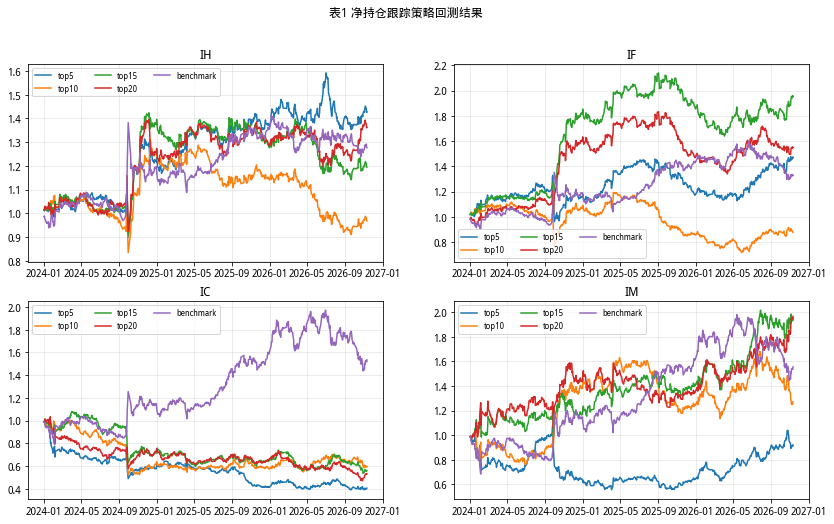

In [11]:
def signal_net_position_follow(features, top_n, product):
    """净持仓变化为正做多, 为负做空, 无变化维持上一持仓"""
    net_change = features['net_change_%d' % top_n]
    return make_signal(features.index, net_change > 0, net_change < 0)


result, net_values = backtest_strategy(signal_net_position_follow, use_top_n=True)
show_strategy_report('表1 净持仓跟踪策略回测结果', result, net_values)
all_strategy_results['净持仓跟踪(表1)'] = result

### 一、持仓方向的指向性 —— 持仓与行情共振: 价格趋势单因子 (表2)


============================== 表2 价格趋势策略回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                无    5.64%     19.59%     0.29  -33.35%  50.36%       332   48.05%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                无   -5.20%     21.12%    -0.25  -43.19%  46.74%       372   53.84%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.00%
 IC                无    8.65%     28.29%     0.31  -30.16%  48.05%       378   54.70%
 IC                 -   18.90%     28.27%     0.67  -27.08%  49.93%         0    0.00%
 IM                无   13.11%     31.06%     0.42  -37.46%  47.32%       366   52.97%
 IM                 -   20.21%     31.05%     0.65  -30.82%  49.93%         0    0.00%
注: 基准策略为当季合约多头滚动持有, 跟踪席位排名记为"-"; 未计交易成本。


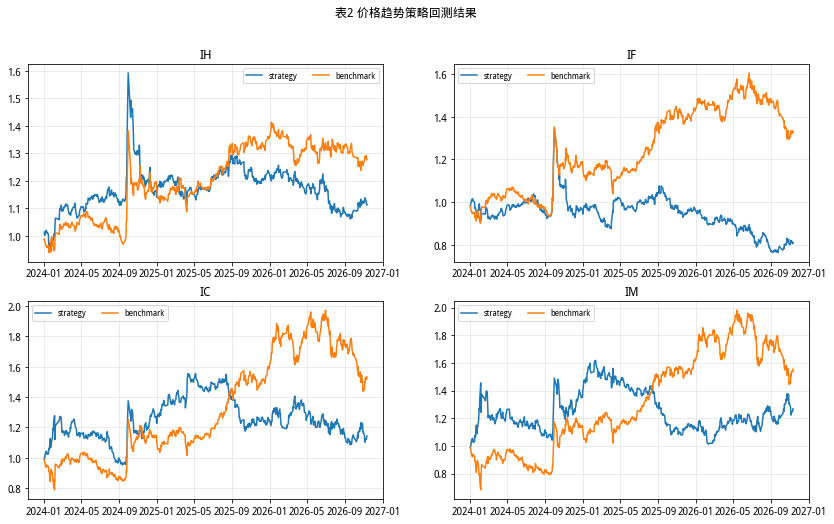

In [12]:
def signal_price_trend(features, top_n, product):
    """前一日价格上涨做多, 下跌做空"""
    price_change = features['price_change']
    return make_signal(features.index, price_change > 0, price_change < 0)


result, net_values = backtest_strategy(signal_price_trend, use_top_n=False)
show_strategy_report('表2 价格趋势策略回测结果', result, net_values)
all_strategy_results['价格趋势(表2)'] = result

### 一、持仓方向的指向性 —— 持仓与行情共振: 量价齐趋 (表3)


============================== 表3 量价齐趋策略回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5   14.37%     19.58%     0.73  -22.38%  51.23%       160   23.15%
 IH                10    3.90%     19.60%     0.20  -28.72%  47.90%       153   22.14%
 IH                15   12.29%     19.58%     0.63  -24.58%  49.06%       139   20.12%
 IH                20   10.12%     19.59%     0.52  -20.43%  48.91%       138   19.97%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5    5.83%     21.09%     0.28  -29.12%  48.84%       199   28.80%
 IF                10    1.50%     21.10%     0.07  -37.44%  47.97%       173   25.04%
 IF                15    4.86%     21.09%     0.23  -36.55%  48.55%       148   21.42%
 IF                20   15.58%     21.10%     0.74  -19.72%  48.91%       145   20.98%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.00%


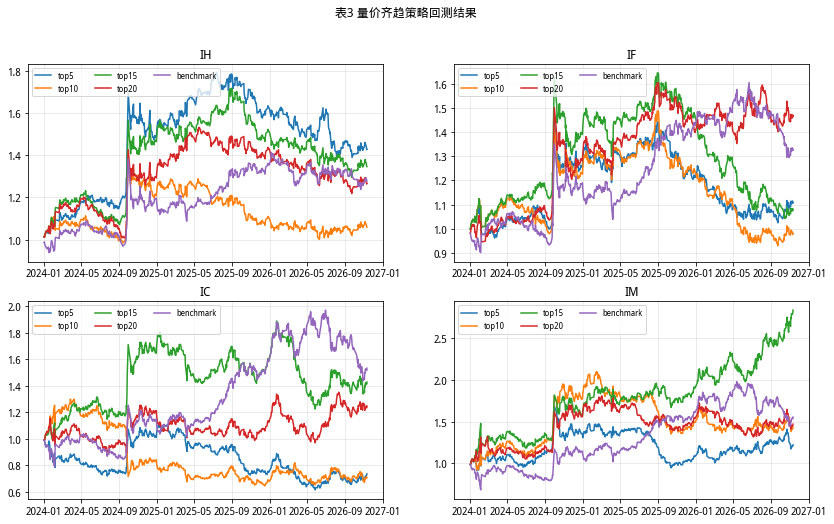

In [13]:
def signal_net_price_resonance(features, top_n, product):
    """净持仓变化与价格变化同为正做多, 同为负做空, 其余维持上一持仓"""
    net_change, price_change = features['net_change_%d' % top_n], features['price_change']
    return make_signal(features.index, (net_change > 0) & (price_change > 0), (net_change < 0) & (price_change < 0))


result, net_values = backtest_strategy(signal_net_price_resonance, use_top_n=True)
show_strategy_report('表3 量价齐趋策略回测结果', result, net_values)
all_strategy_results['量价齐趋(表3)'] = result

### 一、持仓方向的指向性 —— 持仓与行情背离 (表4)


============================== 表4 量价背离策略回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5    5.97%     19.58%     0.31  -43.14%  51.23%       176   25.47%
 IH                10    0.33%     19.58%     0.02  -48.93%  48.91%       175   25.33%
 IH                15    2.27%     19.58%     0.12  -45.23%  48.48%       177   25.62%
 IH                20    0.91%     19.58%     0.05  -43.51%  49.42%       180   26.05%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5   18.93%     21.09%     0.90  -27.68%  54.41%       166   24.02%
 IF                10    1.11%     21.12%     0.05  -27.99%  51.23%       174   25.18%
 IF                15   12.68%     21.11%     0.60  -27.68%  51.81%       208   30.10%
 IF                20    4.59%     21.08%     0.22  -35.13%  51.45%       207   29.96%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.00%


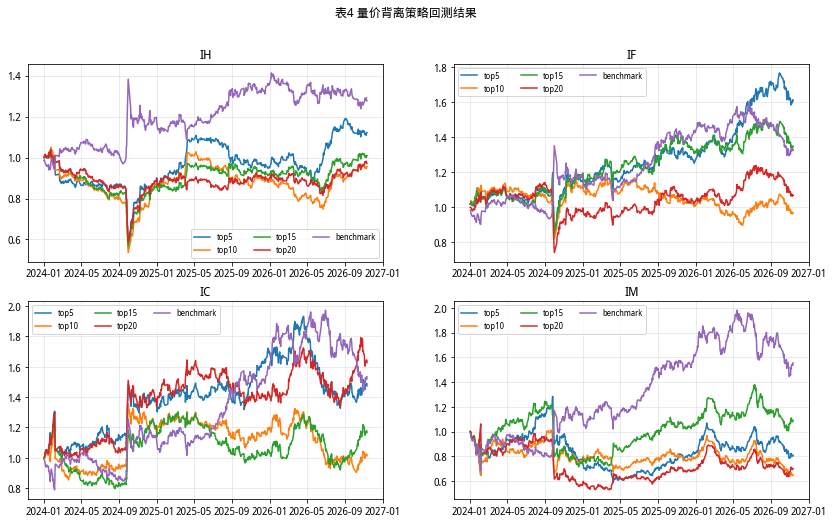

In [14]:
def signal_net_price_divergence(features, top_n, product):
    """净持仓与价格背离: IH/IF/IM 跟随净持仓方向, IC 跟随价格方向"""
    net_change, price_change = features['net_change_%d' % top_n], features['price_change']
    follow_net_long, follow_net_short = (net_change > 0) & (price_change < 0), (net_change < 0) & (price_change > 0)
    if product == 'IC':
        return make_signal(features.index, follow_net_short, follow_net_long)
    return make_signal(features.index, follow_net_long, follow_net_short)


result, net_values = backtest_strategy(signal_net_price_divergence, use_top_n=True)
show_strategy_report('表4 量价背离策略回测结果', result, net_values)
all_strategy_results['量价背离(表4)'] = result

### 二、蜘蛛网策略再探 —— 多空持仓 (表5)


============================== 表5 多空持仓(蜘蛛网)策略回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5   14.41%     19.31%     0.75  -17.85%  48.88%        43    6.22%
 IH                10   19.99%     19.53%     1.02  -18.28%  50.66%        37    5.35%
 IH                15   21.59%     19.52%     1.11  -15.96%  50.22%        21    3.04%
 IH                20   21.37%     19.52%     1.09  -12.09%  49.78%        27    3.91%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5   -6.47%     21.09%    -0.31  -35.50%  50.22%        36    5.21%
 IF                10    2.21%     20.91%     0.11  -31.65%  51.41%        20    2.89%
 IF                15   -6.23%     20.91%    -0.30  -43.38%  50.81%        14    2.03%
 IF                20  -12.01%     20.86%    -0.58  -39.13%  49.70%        11    1.59%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0

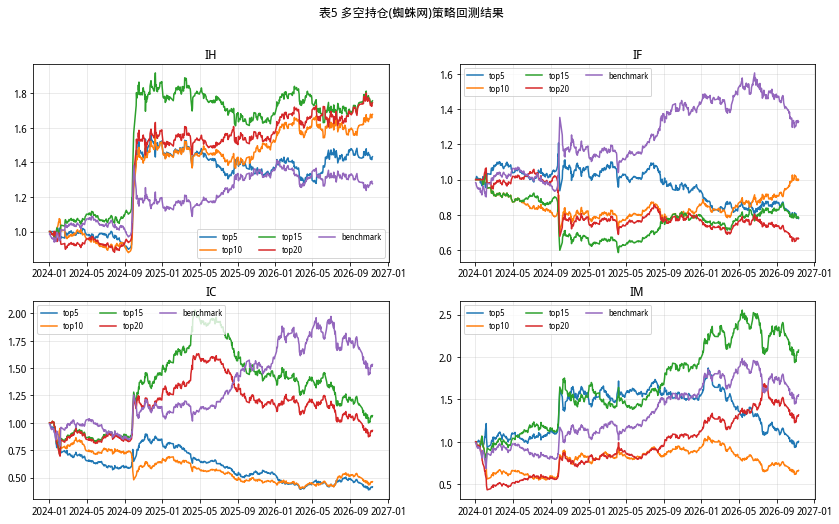

In [15]:
def signal_spider_web(features, top_n, product):
    """多头持仓增加且空头持仓减少做多; 多头减少且空头增加做空"""
    long_change, short_change = features['long_change_%d' % top_n], features['short_change_%d' % top_n]
    return make_signal(features.index, (long_change > 0) & (short_change < 0), (long_change < 0) & (short_change > 0))


result, net_values = backtest_strategy(signal_spider_web, use_top_n=True)
show_strategy_report('表5 多空持仓(蜘蛛网)策略回测结果', result, net_values)
all_strategy_results['多空持仓蜘蛛网(表5)'] = result

### 二、蜘蛛网策略再探 —— 持仓行情共振策略1 (表6)


============================== 表6 持仓行情共振策略1回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5   12.95%     19.32%     0.67  -19.04%  49.55%        20    2.89%
 IH                10   11.04%     19.32%     0.57  -20.05%  50.30%        12    1.74%
 IH                15    8.31%     18.85%     0.44  -21.33%  48.28%         7    1.01%
 IH                20    4.41%     19.55%     0.23  -21.33%  49.27%        10    1.45%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5   12.92%     21.08%     0.61  -21.25%  51.38%        19    2.75%
 IF                10   19.17%     20.34%     0.94  -21.25%  52.07%         9    1.30%
 IF                15   -4.93%     20.88%    -0.24  -45.17%  50.74%        10    1.45%
 IF                20   -7.49%     20.87%    -0.36  -44.35%  50.89%         7    1.01%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.0

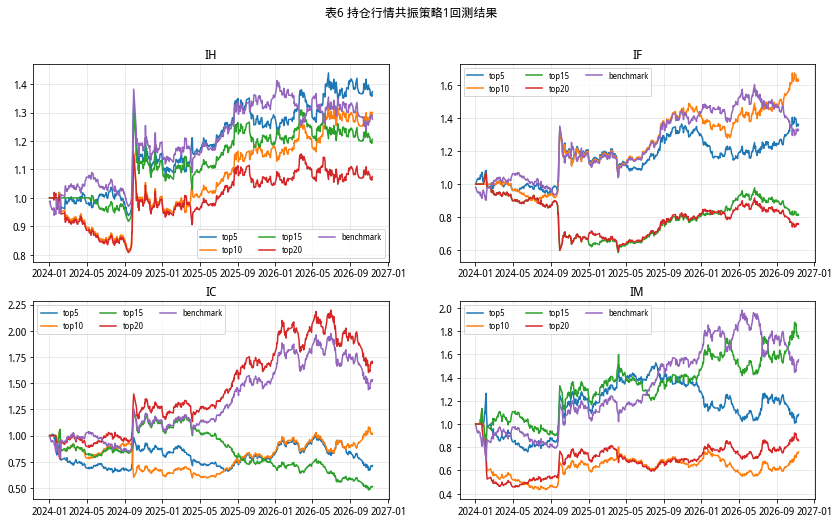

In [16]:
def signal_spider_web_with_price(features, top_n, product):
    """蜘蛛网信号 + 价格方向同向: 多头增/空头减且价格涨做多; 多头减/空头增且价格跌做空"""
    long_change, short_change = features['long_change_%d' % top_n], features['short_change_%d' % top_n]
    price_change = features['price_change']
    return make_signal(features.index,
                       (long_change > 0) & (short_change < 0) & (price_change > 0),
                       (long_change < 0) & (short_change > 0) & (price_change < 0))


result, net_values = backtest_strategy(signal_spider_web_with_price, use_top_n=True)
show_strategy_report('表6 持仓行情共振策略1回测结果', result, net_values)
all_strategy_results['持仓行情共振1(表6)'] = result

### 二、蜘蛛网策略再探 —— 持仓行情共振策略2: 多空同增同减 (表7)


============================== 表7 持仓行情共振策略2回测结果 ==============================
品种 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤    胜率  信号次数 信号频率
 IH                 5    3.29%     19.60%     0.17  -29.90%  50.80%        84   12.16%
 IH                10    1.96%     19.60%     0.10  -29.37%  48.91%        81   11.72%
 IH                15   12.28%     19.58%     0.63  -22.29%  50.22%        66    9.55%
 IH                20   10.70%     19.59%     0.55  -18.25%  49.49%        66    9.55%
 IH                 -   10.44%     19.59%     0.53  -21.33%  51.23%         0    0.00%
 IF                 5   25.08%     20.95%     1.20  -16.58%  51.33%        82   11.87%
 IF                10   10.47%     21.09%     0.50  -37.51%  49.35%        76   11.00%
 IF                15    8.78%     21.09%     0.42  -39.06%  48.48%        62    8.97%
 IF                20   18.07%     21.06%     0.86  -19.27%  48.91%        60    8.68%
 IF                 -   12.12%     21.11%     0.57  -23.12%  49.78%         0    0.0

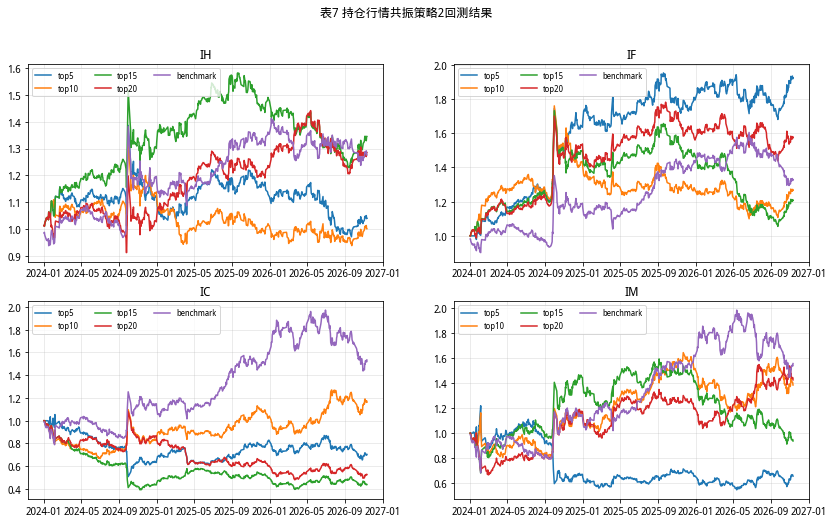

In [17]:
def signal_both_sides_with_price(features, top_n, product):
    """多空持仓同增(多>空>0)且价格涨 / 同减(多<空<0)且价格跌; IH/IF 顺势, IC/IM 反向"""
    long_change, short_change = features['long_change_%d' % top_n], features['short_change_%d' % top_n]
    price_change = features['price_change']
    both_increase = (long_change > short_change) & (short_change > 0) & (price_change > 0)
    both_decrease = (long_change < short_change) & (short_change < 0) & (price_change < 0)
    if product in LARGE_CAP_PRODUCTS:
        return make_signal(features.index, both_increase, both_decrease)
    return make_signal(features.index, both_decrease, both_increase)


result, net_values = backtest_strategy(signal_both_sides_with_price, use_top_n=True)
show_strategy_report('表7 持仓行情共振策略2回测结果', result, net_values)
all_strategy_results['持仓行情共振2(表7)'] = result

### 总结 —— 各品种不同策略择优 (摘要)

In [18]:
def select_best_strategy_per_product(all_strategy_results):
    """剔除基准后, 每个品种按夏普比率选出最优的 (策略, 席位排名)"""
    tables = []
    for strategy_name, result in all_strategy_results.items():
        table = result[result['跟踪席位排名(<=n)'] != '-'].copy()
        table.insert(0, '策略', strategy_name)
        tables.append(table)
    candidates = pd.concat(tables).dropna(subset=['夏普比率'])
    best = candidates.sort_values('夏普比率', ascending=False).groupby('品种').head(1).set_index('品种')
    best = best.reindex([product for product in PRODUCTS if product in best.index]).reset_index()
    return best[['品种', '策略', '跟踪席位排名(<=n)', '年化收益', '年化波动率', '夏普比率', '最大回撤']]


best_strategy_table = select_best_strategy_per_product(all_strategy_results)
print('\n' + '=' * 30 + ' 总结: 各品种不同策略择优 (按夏普比率) ' + '=' * 30)
print(format_result_table(best_strategy_table).to_string(index=False))


============================== 总结: 各品种不同策略择优 (按夏普比率) ==============================
品种                 策略 跟踪席位排名(<=n) 年化收益 年化波动率 夏普比率 最大回撤
 IH  多空持仓蜘蛛网(表5)                15   21.59%     19.52%     1.11  -15.96%
 IF      净持仓跟踪(表1)                15   25.62%     21.06%     1.22  -23.40%
 IC   持仓行情共振1(表6)                20   22.54%     27.80%     0.81  -27.08%
 IM        量价齐趋(表3)                15   41.33%     30.96%     1.33  -19.94%


### 风险提示

In [ ]:
print('\n风险提示: 回测基于历史数据, 有失效风险。')